SETUP

In [1]:
pip install tensorflow[and-cuda] opencv-python matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip list

Package                  Version
------------------------ -----------
absl-py                  2.4.0
asttokens                3.0.1
astunparse               1.6.3
certifi                  2026.2.25
charset-normalizer       3.4.4
comm                     0.2.3
contourpy                1.3.2
cycler                   0.12.1
debugpy                  1.8.20
decorator                5.2.1
exceptiongroup           1.3.1
executing                2.2.1
flatbuffers              25.12.19
fonttools                4.61.1
gast                     0.7.0
google-pasta             0.2.0
grpcio                   1.78.0
h5py                     3.15.1
idna                     3.11
ipykernel                7.2.0
ipython                  8.38.0
jedi                     0.19.2
jupyter_client           8.8.0
jupyter_core             5.9.1
keras                    3.12.1
kiwisolver               1.4.9
libclang                 18.1.1
Markdown                 3.10.2
markdown-it-py           4.0.0
MarkupSafe     

In [3]:
import tensorflow as tf
import os 

2026-03-01 15:26:04.773468: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-03-01 15:26:04.923103: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-03-01 15:26:08.510423: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [4]:
gpus = tf.config.experimental.list_physical_devices('GPU')

In [5]:
gpus

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [6]:
#avoid oom error
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

In [7]:
import cv2
import imghdr

Images

In [8]:
data_dir = 'data'

In [9]:
image_exts = ['jpg', 'jpeg', 'bmp', 'png']

In [10]:
image_exts[2]

'bmp'

In [11]:
for image_class in os.listdir(data_dir):
    print(image_class)

BirdData
TestData
ValData


In [12]:
#loop through folders and images to remove bad images
for image_class in os.listdir(data_dir):
    for image in os.listdir(os.path.join(data_dir, image_class)):
        image_path = os.path.join(data_dir, image_class, image)
        try:
            img = cv2.imread(image_path)
            tip = imghdr.what(image_path)
            if tip not in image_exts:
                print('Image not found {}'.format(image_path))
                os.remove(image_path)
        except Exception as e:
            print('image with image {}'.format(image_path))

image with image data/BirdData/ABBOTTS BABBLER
image with image data/BirdData/ABBOTTS BOOBY
image with image data/BirdData/ABYSSINIAN GROUND HORNBILL
image with image data/BirdData/AFRICAN CROWNED CRANE
image with image data/BirdData/AFRICAN EMERALD CUCKOO
image with image data/BirdData/AFRICAN FIREFINCH
image with image data/BirdData/AFRICAN OYSTER CATCHER
image with image data/BirdData/AFRICAN PIED HORNBILL
image with image data/BirdData/AFRICAN PYGMY GOOSE
image with image data/BirdData/ALBATROSS
image with image data/BirdData/ALBERTS TOWHEE
image with image data/BirdData/ALEXANDRINE PARAKEET
image with image data/BirdData/ALPINE CHOUGH
image with image data/BirdData/ALTAMIRA YELLOWTHROAT
image with image data/BirdData/AMERICAN AVOCET
image with image data/BirdData/AMERICAN BITTERN
image with image data/BirdData/AMERICAN COOT
image with image data/BirdData/AMERICAN DIPPER
image with image data/BirdData/AMERICAN FLAMINGO
image with image data/BirdData/AMERICAN GOLDFINCH
image with im

LOAD DATA

In [13]:
import numpy as np
from matplotlib import pyplot as plt

In [ ]:
#organizes, shuffle, resizes, cleans up data

#changes batch size to 16 insted of default 32
#data = tf.keras.utils.image_dataset_from_directory('data', batch_size = 16)

#data = tf.keras.utils.image_dataset_from_directory('data/BirdData', image_size=(224,224))
#valData = tf.keras.utils.image_dataset_from_directory('data/ValData', image_size=(224,224))
#testData = tf.keras.utils.image_dataset_from_directory('data/TestData', image_size=(224,224))

data = tf.keras.utils.image_dataset_from_directory("data/BirdData", image_size=(224, 224), batch_size=16)

Found 84635 files belonging to 525 classes.
Using 67708 files for training.
Found 2625 files belonging to 525 classes.
Using 525 files for validation.


In [15]:
data_iterator = data.as_numpy_iterator()

In [16]:
#gets a batch from iterator
batch = data_iterator.next()

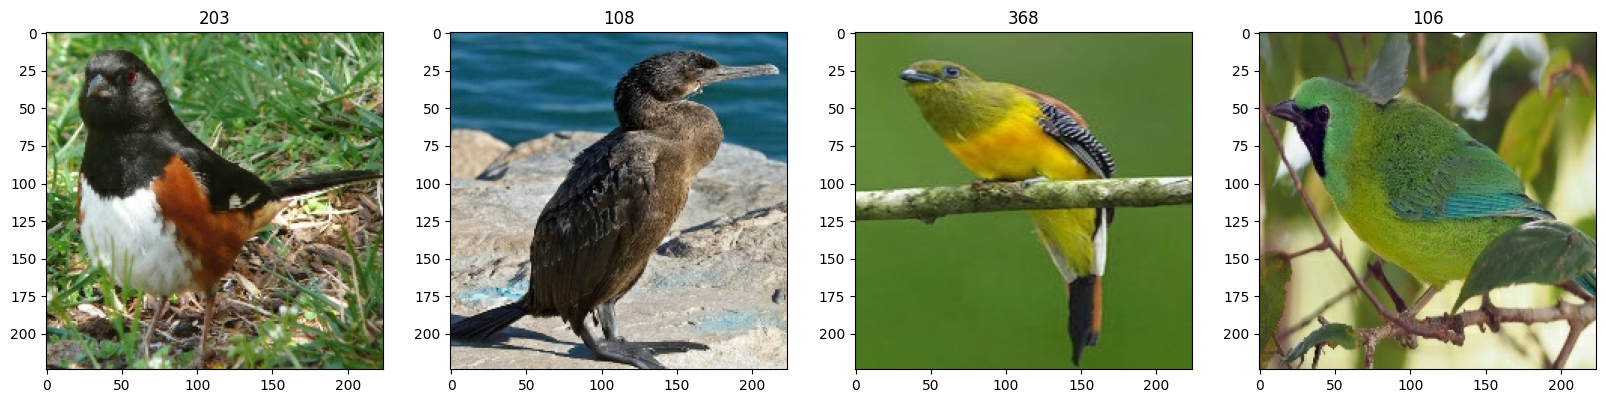

In [17]:
fig, ax = plt.subplots(ncols = 4, figsize = (20,20))
for idx, img in enumerate(batch[0][:4]):
    ax[idx].imshow(img.astype(int))
    ax[idx].title.set_text(batch[1][idx])

SCALE DATA

In [18]:
data = data.map(lambda x,y:(x/255, y))

In [19]:
scaled_iterator = data.as_numpy_iterator()

In [20]:
batch = scaled_iterator.next()

In [21]:
batch

(array([[[[0.9882353 , 0.9882353 , 0.99607843],
          [0.9882353 , 0.9882353 , 0.99607843],
          [0.9882353 , 0.9882353 , 0.99607843],
          ...,
          [0.9882353 , 0.9882353 , 0.9882353 ],
          [0.9882353 , 0.9882353 , 0.9882353 ],
          [0.9882353 , 0.9882353 , 0.9882353 ]],
 
         [[0.9882353 , 0.9882353 , 0.99607843],
          [0.9882353 , 0.9882353 , 0.99607843],
          [0.9882353 , 0.9882353 , 0.99607843],
          ...,
          [0.9882353 , 0.9882353 , 0.9882353 ],
          [0.9882353 , 0.9882353 , 0.9882353 ],
          [0.9882353 , 0.9882353 , 0.9882353 ]],
 
         [[0.9882353 , 0.9882353 , 0.99607843],
          [0.9882353 , 0.9882353 , 0.99607843],
          [0.9882353 , 0.9882353 , 0.99607843],
          ...,
          [0.9882353 , 0.9882353 , 0.9882353 ],
          [0.9882353 , 0.9882353 , 0.9882353 ],
          [0.9882353 , 0.9882353 , 0.9882353 ]],
 
         ...,
 
         [[0.5254902 , 0.6666667 , 0.7294118 ],
          [0.52549

In [22]:
len(data)

2645

In [23]:
train_size = int(len(data)*.7)
val_size = int(len(data)*.25)
test_size = int(len(data)*.05)

In [26]:
train_size = int(len(data))
val_size = int(len(valData))
test_size = int(len(testData))

In [24]:
train_size

1851

In [25]:
train = data.take(train_size)
val = data.skip(train_size).take(val_size)
test = data.skip(train_size + val_size).take(train_size)

BUILD MODEL

In [26]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.callbacks import ModelCheckpoint

In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])

In [27]:
model = Sequential()

In [ ]:
data_augmentation
model.add(Conv2D(32, (3,3), 1, activation='relu', input_shape=(224,224,3)))
model.add(MaxPooling2D())

model.add(Conv2D(64, (3,3), 1, activation='relu'))
model.add(MaxPooling2D())

model.add(Conv2D(128, (3,3), 1, activation='relu'))
model.add(MaxPooling2D())

model.add(Conv2D(256, (3,3), 1, activation='relu'))
model.add(MaxPooling2D())

model.add(GlobalAveragePooling2D())

model.add(Dense(224, activation = 'relu'))
model.add(Dropout(0.3))
#= number of classes, softmax activation because more than 1 class
model.add(Dense(525, activation='softmax'))

/home/kaartik/project-env/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [29]:
model.compile('adam', loss=tf.keras.losses.SparseCategoricalCrossentropy(), metrics=['accuracy'])

In [30]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 224)            │        57,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 224)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 525)            │       118,125 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 564,109 (2.15 MB)

 Trainable params: 564,109 (2.15 MB)

 Non-trainable params: 0 (0.00 B)

TRAIN

In [31]:
logdir = 'logs'

In [32]:
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=logdir)

In [35]:
checkpoint = ModelCheckpoint(
    'best_model.h5',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

In [36]:
hist = model.fit(train, epochs = 50, validation_data=val, callbacks=[tensorboard_callback])

Epoch 1/50


2026-03-01 15:28:01.700415: I external/local_xla/xla/service/service.cc:163] XLA service 0x7119c01133d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-03-01 15:28:01.700621: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9
2026-03-01 15:28:01.869213: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-03-01 15:28:02.884816: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91900
2026-03-01 15:28:03.439180: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-03-01 15:28:03.

1851/1851 ━━━━━━━━━━━━━━━━━━━━ 343s 173ms/step - accuracy: 0.0048 - loss: 6.0422 - val_accuracy: 0.0113 - val_loss: 5.7441
Epoch 2/50
1851/1851 ━━━━━━━━━━━━━━━━━━━━ 429s 232ms/step - accuracy: 0.0211 - loss: 5.4795 - val_accuracy: 0.0467 - val_loss: 5.1258
Epoch 3/50
1851/1851 ━━━━━━━━━━━━━━━━━━━━ 203s 109ms/step - accuracy: 0.0604 - loss: 4.9285 - val_accuracy: 0.1062 - val_loss: 4.5413
Epoch 4/50
1851/1851 ━━━━━━━━━━━━━━━━━━━━ 204s 110ms/step - accuracy: 0.1110 - loss: 4.4423 - val_accuracy: 0.1684 - val_loss: 4.0756
Epoch 5/50
1851/1851 ━━━━━━━━━━━━━━━━━━━━ 206s 111ms/step - accuracy: 0.1567 - loss: 4.0842 - val_accuracy: 0.2188 - val_loss: 3.7758
Epoch 6/50
1851/1851 ━━━━━━━━━━━━━━━━━━━━ 208s 112ms/step - accuracy: 0.2034 - loss: 3.7758 - val_accuracy: 0.2633 - val_loss: 3.5084
Epoch 7/50
1851/1851 ━━━━━━━━━━━━━━━━━━━━ 208s 112ms/step - accuracy: 0.2431 - loss: 3.5034 - val_accuracy: 0.3059 - val_loss: 3.2711
Epoch 8/50
1851/1851 ━━━━━━━━━━━━━━━━━━━━ 252s 136ms/step - accuracy: 0.2

2026-03-01 16:12:48.211796: W tensorflow/core/kernels/data/prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 19268096 bytes after encountering the first element of size 19268096 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


1851/1851 ━━━━━━━━━━━━━━━━━━━━ 208s 112ms/step - accuracy: 0.3751 - loss: 2.7419 - val_accuracy: 0.4309 - val_loss: 2.6227
Epoch 12/50
1851/1851 ━━━━━━━━━━━━━━━━━━━━ 204s 110ms/step - accuracy: 0.4029 - loss: 2.5999 - val_accuracy: 0.4438 - val_loss: 2.5434
Epoch 13/50
1851/1851 ━━━━━━━━━━━━━━━━━━━━ 205s 110ms/step - accuracy: 0.4235 - loss: 2.4780 - val_accuracy: 0.4679 - val_loss: 2.4493
Epoch 14/50
1851/1851 ━━━━━━━━━━━━━━━━━━━━ 204s 110ms/step - accuracy: 0.4435 - loss: 2.3682 - val_accuracy: 0.4816 - val_loss: 2.3653
Epoch 15/50
1851/1851 ━━━━━━━━━━━━━━━━━━━━ 204s 110ms/step - accuracy: 0.4641 - loss: 2.2647 - val_accuracy: 0.4890 - val_loss: 2.3294
Epoch 16/50
1851/1851 ━━━━━━━━━━━━━━━━━━━━ 204s 110ms/step - accuracy: 0.4856 - loss: 2.1611 - val_accuracy: 0.5046 - val_loss: 2.2433
Epoch 17/50
1851/1851 ━━━━━━━━━━━━━━━━━━━━ 207s 112ms/step - accuracy: 0.4976 - loss: 2.0886 - val_accuracy: 0.5214 - val_loss: 2.1836
Epoch 18/50
1851/1851 ━━━━━━━━━━━━━━━━━━━━ 202s 109ms/step - accura

2026-03-01 17:40:18.783246: W tensorflow/core/kernels/data/prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 19268096 bytes after encountering the first element of size 19268096 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


... (5 outputs left out)

2026-03-01 18:32:45.916484: W tensorflow/core/kernels/data/prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 19268096 bytes after encountering the first element of size 19268096 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


1851/1851 ━━━━━━━━━━━━━━━━━━━━ 205s 111ms/step - accuracy: 0.7299 - loss: 0.9615 - val_accuracy: 0.6058 - val_loss: 2.0369
Epoch 50/50
1851/1851 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.7339 - loss: 0.9405

2026-03-01 18:36:08.656348: W tensorflow/core/kernels/data/prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 19268096 bytes after encountering the first element of size 19268096 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


1851/1851 ━━━━━━━━━━━━━━━━━━━━ 203s 110ms/step - accuracy: 0.7345 - loss: 0.9411 - val_accuracy: 0.6078 - val_loss: 2.0371


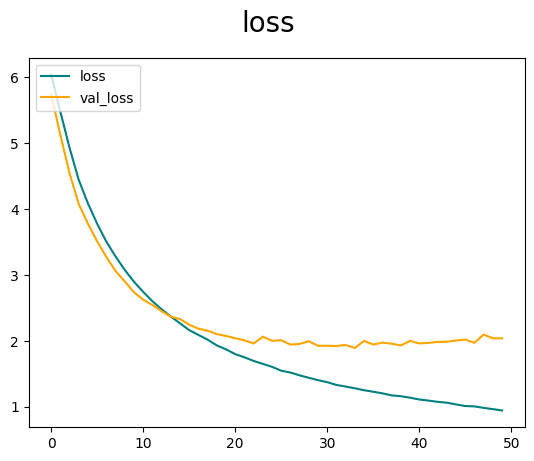

In [37]:
fig = plt.figure()
plt.plot(hist.history['loss'], color = 'teal', label = 'loss')
plt.plot(hist.history['val_loss'], color = 'orange', label = 'val_loss')
fig.suptitle('loss', fontsize=20)
plt.legend(loc = "upper left")
plt.show()

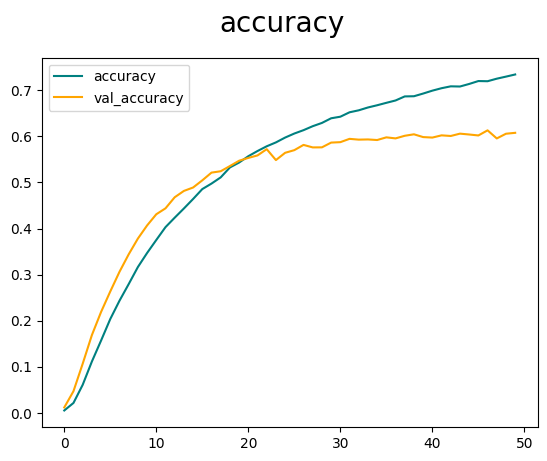

In [38]:
fig = plt.figure()
plt.plot(hist.history['accuracy'], color = 'teal', label = 'accuracy')
plt.plot(hist.history['val_accuracy'], color = 'orange', label = 'val_accuracy')
fig.suptitle('accuracy', fontsize=20)
plt.legend(loc = "upper left")
plt.show()

EVALUATE

In [39]:
from tensorflow.keras.metrics import Precision, Recall, SparseCategoricalAccuracy

In [40]:
pre = Precision(top_k=1)
re = Recall(top_k=1)
acc = SparseCategoricalAccuracy()

In [41]:
for batch in test.as_numpy_iterator():
    x,y = batch
    yhat = model.predict(x)
    #pre.update_state(y, yhat)
    #re.update_state(y, yhat)
    acc.update_state(y, yhat)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 240ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 187ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 219ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 

2026-03-01 19:13:59.825505: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [42]:
print(f'Accucacy: {acc.result().numpy()}')

Accucacy: 0.5916255116462708


TEST

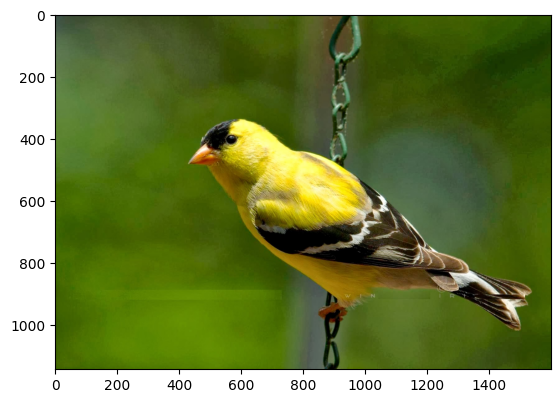

In [43]:
#loads happy test image

#load sad image -> img = cv2.imread('sadperson.jpg')
img = cv2.imread('american goldfinch.png')
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

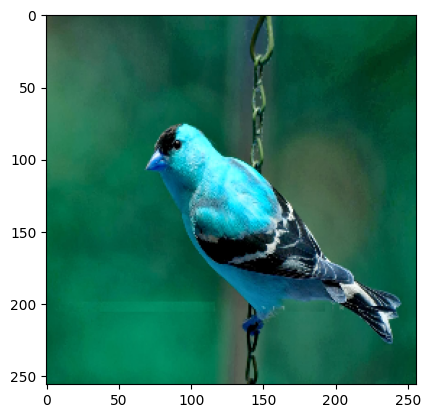

In [45]:
#resized to 256 256 for model
resize = tf.image.resize(img, (256,256))
plt.imshow(resize.numpy().astype(int))
plt.show

In [46]:
#tests with the model
yhat = model.predict(np.expand_dims(resize/256, 0))

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


In [47]:
yhat

array([[2.43015413e-10, 2.49120717e-06, 2.67372104e-17, 4.70082529e-23,
        6.95574721e-16, 9.65405300e-36, 4.34233597e-36, 9.81941199e-13,
        2.55069844e-17, 2.47323995e-10, 2.71161977e-12, 8.37769776e-23,
        4.22623395e-24, 3.30781382e-13, 1.57278108e-12, 2.07862256e-16,
        3.06130311e-22, 6.67989901e-14, 1.83738973e-23, 2.11522070e-13,
        3.32975931e-17, 1.23317616e-13, 1.64356223e-14, 2.85416403e-24,
        2.66730838e-13, 6.09009024e-11, 1.56166323e-17, 9.29361015e-12,
        1.03678849e-12, 2.83484888e-17, 2.28734868e-16, 2.73804178e-12,
        2.92359317e-13, 9.34160801e-24, 1.18957230e-28, 1.97460578e-28,
        1.45280413e-20, 4.70351091e-10, 1.58689700e-10, 1.56220504e-25,
        1.16622367e-09, 1.73629779e-15, 3.63359542e-09, 4.60467385e-12,
        1.59055311e-23, 5.67185077e-10, 7.31561480e-29, 1.60731248e-25,
        1.42769677e-05, 4.57870242e-10, 3.33722591e-01, 6.37472937e-08,
        1.02925294e-14, 8.70856938e-23, 9.46716784e-24, 1.767788

In [48]:
max_idx = np.argmax(yhat)

In [49]:
max_idx

np.int64(482)

In [50]:
confidence = np.max(yhat)

In [59]:
data_dir = 'data/BirdData'

In [60]:
birdnames = []
for image_class in os.listdir(data_dir):
    birdnames.append(image_class)
print(birdnames[max_idx])

TREE SWALLOW


In [52]:
from tensorflow.keras.models import load_model

In [53]:
model.save(os.path.join('models', 'BirdAI-v2.h5'))

In [10]:
new_model = load_model(os.path.join('models', 'BirdAI-v1.h5'))

I0000 00:00:1772317615.407294     688 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5563 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


In [17]:
yhat_new = new_model.predict(np.expand_dims(resize/255, 0))

2026-02-28 16:28:50.380147: I external/local_xla/xla/service/service.cc:163] XLA service 0x738fc4019720 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-02-28 16:28:50.380209: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9
2026-02-28 16:28:50.411380: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-02-28 16:28:50.502748: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91900


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


I0000 00:00:1772317732.547847    2058 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


In [18]:
yhat_new

array([[9.12537471e-39, 1.13922134e-29, 1.59560989e-35, 2.44688545e-03,
        0.00000000e+00, 9.93016485e-32, 0.00000000e+00, 2.87012034e-26,
        4.83444849e-16, 0.00000000e+00, 8.84761061e-26, 1.31711864e-33,
        1.39332911e-07, 6.47787999e-07, 1.04350615e-02, 1.11387136e-30,
        0.00000000e+00, 4.30171724e-39, 2.91230440e-27, 2.01786979e-43,
        1.06574436e-18, 2.83508805e-29, 1.35947362e-32, 0.00000000e+00,
        2.19874267e-34, 1.27331367e-39, 9.35513759e-04, 4.24803264e-32,
        1.18398592e-33, 1.09835702e-29, 2.64586877e-08, 5.87120288e-19,
        2.93003400e-19, 2.34769281e-35, 2.25571218e-40, 1.55105868e-31,
        3.60942190e-28, 4.05360051e-14, 3.77508071e-32, 1.77734617e-33,
        8.75499802e-37, 0.00000000e+00, 1.01626357e-22, 7.58595668e-30,
        7.66510260e-43, 0.00000000e+00, 0.00000000e+00, 1.68208836e-35,
        2.15872309e-21, 0.00000000e+00, 0.00000000e+00, 1.40129846e-45,
        0.00000000e+00, 2.66430137e-16, 1.21247350e-40, 1.036547

In [28]:
max_idx = np.argmax(yhat_new)

In [29]:
birdnames = []
for image_class in os.listdir(data_dir):
    birdnames.append(image_class)
print(birdnames[max_idx])

122.Harris_Sparrow
